In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv("../API/resultats_vies.csv")
df.head()

,isValid,requestDate,userError,name,address,requestIdentifier,originalVatNumber,vatNumber,viesApproximate,numero_tva_normalise
0,False,2026-11-18T16:54:20.878Z,INVALID,NaN,NaN,NaN,28547277,28547277,"{'name': '---', 'street': '---', 'postalCode':...",DK28547277
1,False,2026-11-18T16:54:31.204Z,INVALID,NaN,NaN,NaN,244701962,244701962,"{'name': '---', 'street': '---', 'postalCode':...",PT244701962
2,False,2026-11-18T17:00:14.757Z,INVALID,NaN,NaN,NaN,450308413,450308413,"{'name': '---', 'street': '---', 'postalCode':...",PT450308413
3,False,2026-11-18T17:00:53.220Z,INVALID,NaN,NaN,NaN,124917823B86,124917823B86,"{'name': '---', 'street': '---', 'postalCode':...",NL124917823B86
4,False,2026-11-18T17:01:03.579Z,INVALID,NaN,NaN,NaN,613111575,613111575,"{'name': '---', 'street': '---', 'postalCode':...",PT613111575


In [17]:
df["isValid"].value_counts()

isValid
False    171
True       8
Name: count, dtype: int64

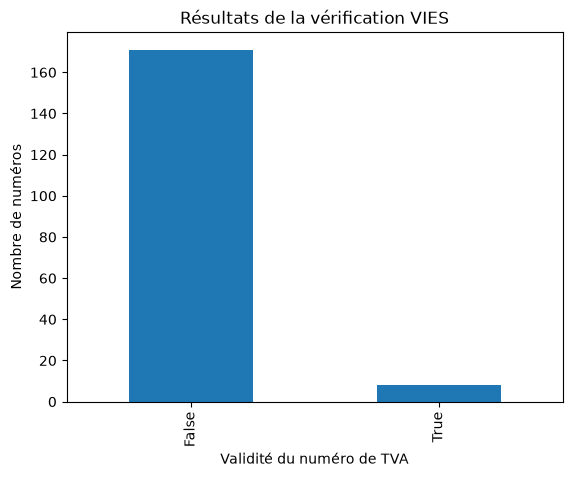

In [18]:
df["isValid"].value_counts().plot(kind="bar")
plt.title("Résultats de la vérification VIES")
plt.xlabel("Validité du numéro de TVA")
plt.ylabel("Nombre de numéros")
plt.show()

In [ ]:
resultats = pd.Series({"Valides": 8,"Invalides": 171,"Non tranchés": 21})

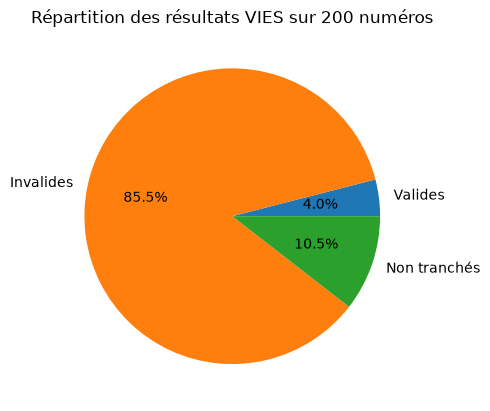

In [20]:
resultats.plot(kind="pie", autopct="%1.1f%%")

plt.title("Répartition des résultats VIES sur 200 numéros")
plt.ylabel("")
plt.show()

In [21]:
df["pays"] = df["numero_tva_normalise"].str[:2]
df["pays"].value_counts()

pays
LU    25
SE    23
PL    21
PT    20
NL    20
FI    18
IT    18
BE    15
DK    14
FR     5
Name: count, dtype: int64

In [22]:
pd.crosstab(df["pays"], df["isValid"])

isValid,False,True
pays,,
BE,15,0
DK,14,0
FI,14,4
FR,4,1
IT,18,0
LU,22,3
NL,20,0
PL,21,0
PT,20,0


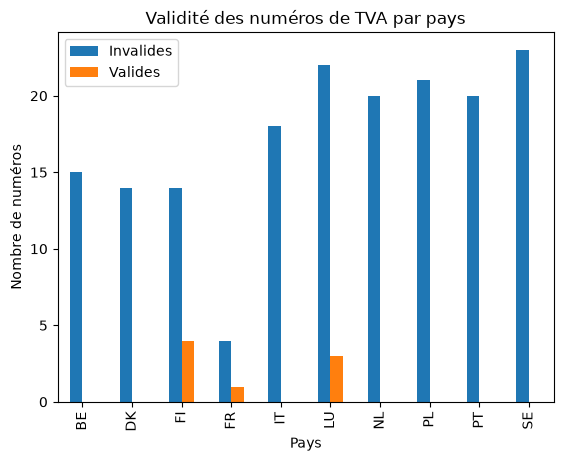

In [23]:
pd.crosstab(df["pays"], df["isValid"]).plot(kind="bar")

plt.title("Validité des numéros de TVA par pays")
plt.xlabel("Pays")
plt.ylabel("Nombre de numéros")
plt.legend(["Invalides", "Valides"])
plt.show()


## Analyse des temps de réponse de l'API VIES

In [24]:
with open("../API/collecte_vies.log", "r") as fichier:
    lignes = fichier.readlines()

print(lignes[:5])

['INFO:root:Début de la collecte\n', "INFO:root:Durée de l'appel : 3.058536\n", 'INFO:root:Code HTTP: 200\n', "INFO:root:Durée de l'appel : 0.320053\n", 'INFO:root:Code HTTP: 200\n']


In [25]:
durees = []

for ligne in lignes:
    if "Durée de l'appel" in ligne:
        duree = float(ligne.split(":")[-1].replace("secondes", "").strip())
        durees.append(duree)

print(len(durees))

234


In [26]:
serie_durees = pd.Series(durees)
serie_durees.describe()

count    234.000000
mean       1.315999
std        2.072797
min        0.102041
25%        0.200922
50%        0.412797
75%        1.185137
max       10.026076
dtype: float64

Résultat	Interprétation
Nombre d'appels mesurés	234	Plusieurs collectes et tentatives
Moyenne	1,32 s	Durée moyenne d'un appel
Médiane	0,41 s	La moitié des appels mesurés dure moins de 0,41 s
Minimum	0,10 s	Appel le plus rapide
Maximum	10,03 s	Appel le plus lent
Écart-type	2,07 s	Les durées sont assez dispersées

### Interprétation des temps de réponse

Sur 234 appels mesurés, le temps de réponse moyen de l'API VIES est de 1,32 seconde, avec une médiane de 0,41 seconde.

Les durées varient de 0,10 à 10,03 secondes. L'écart-type de 2,07 secondes montre que les temps de réponse sont variables.

La majorité des appels sont rapides, mais quelques appels plus longs augmentent la moyenne.

Ces mesures comprennent plusieurs collectes et tentatives de vérification.

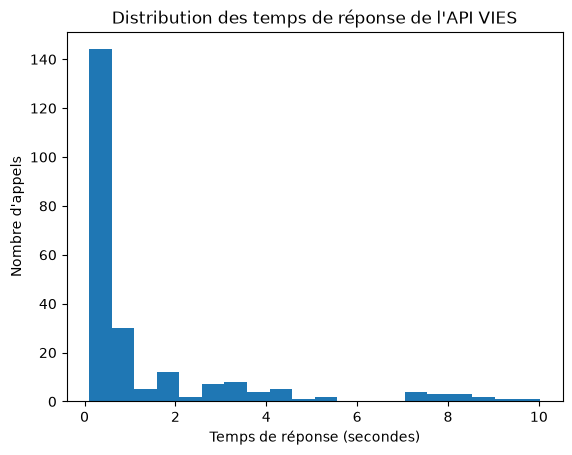

In [27]:
serie_durees.plot(kind="hist", bins=20)

plt.title("Distribution des temps de réponse de l'API VIES")
plt.xlabel("Temps de réponse (secondes)")
plt.ylabel("Nombre d'appels")
plt.show()